# Step 8 — Does the centralised critic matter past the answer key?

**Deliverable 03's step 10 found** that a critic given only the actor's four numbers
(independent PPO) passes the same gates as the centralised critic (MAPPO) at $N=3$ and
$N=5$, and that at $N=7$, where both fail, the centralised critic is measurably better. The
open question was whether that advantage holds, grows or disappears at 10 and 15 players.

**There is no exact answer here, so there is no gate.** The comparison uses the measures this
folder already uses where nothing can be checked:

1. **The switch test (step 2).** For every seat, does switching alone to a simple rule raise
   its chance of winning? A profitable switch proves the policy is not an equilibrium, so
   *fewer and smaller* profitable switches is the closest thing to "better" available here.
2. **Survival of the weakest**, as a multiple of an even share (step 1).
3. **Targeting** by rank and by players left, read against `next_weaker`, the fixed rule
   step 3 found the agent sits on at these sizes.
4. **The critic's explained variance**, as in deliverable 03 step 10.

**This notebook trains nothing.** `train_and_measure.py` in this folder trains and measures
all twenty runs, in parallel, and writes one result file per run into `results/`. Training
runs for over an hour, so it is a script; the analysis is a notebook.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch

from gruel_env import GruelEnv, MISS, SHOOT_LEFT, SHOOT_RIGHT
import train_and_measure as script

PLAYER_COUNTS = script.PLAYER_COUNTS
ARMS = script.ARMS
SEEDS = script.SEEDS
SEED = 0

print("player counts:", PLAYER_COUNTS, " arms:", ARMS, " seeds:", SEEDS)
print("budget per run:", script.UPDATES, "updates x", script.EPISODES_PER_UPDATE, "episodes")
print("measured episodes per run:", script.EVALUATION_EPISODES)
print("switch test: baseline", script.BASELINE_EPISODES, "episodes, each switch",
      script.SWITCH_EPISODES, "episodes, threshold", script.STANDARD_ERRORS, "standard errors")

player counts: [10, 15]  arms: ['centralised', 'local']  seeds: [0, 1, 2, 3, 4]
budget per run: 2000 updates x 96 episodes
measured episodes per run: 10000
switch test: baseline 10000 episodes, each switch 5000 episodes, threshold 3 standard errors


## The result files

One per run. A missing file stops the notebook, rather than letting it analyse a partial set.

In [2]:
R = {}
missing = []
for n in PLAYER_COUNTS:
    for arm in ARMS:
        for seed in SEEDS:
            path = script.result_path(n, arm, seed)
            if not os.path.exists(path):
                missing.append(os.path.basename(path))
                continue
            with open(path) as handle:
                R[(n, arm, seed)] = json.load(handle)

if missing:
    raise FileNotFoundError("run train_and_measure.py first; missing: " + ", ".join(missing))

print("result files read:", len(R))
for n in PLAYER_COUNTS:
    for arm in ARMS:
        minutes = [R[(n, arm, seed)]["total_minutes"] for seed in SEEDS]
        print("  N=%-3d %-11s minutes per run %s" % (n, arm, "  ".join("%.1f" % m for m in minutes)))
versions = set()
for key in R:
    versions.add((R[key]["torch"], R[key]["python"]))
print("torch and python versions across runs:", versions)

result files read: 20
  N=10  centralised minutes per run 16.8  17.0  16.9  17.3  17.5
  N=10  local       minutes per run 16.7  16.6  16.8  16.4  14.4
  N=15  centralised minutes per run 27.8  32.5  27.5  27.4  29.2
  N=15  local       minutes per run 26.6  27.3  26.5  27.4  26.3
torch and python versions across runs: {('2.2.2', '3.11.5')}


## Check: the centralised arm is step 1

Folder 04 step 1 trained the centralised agent at 10 and 15 players on seeds 0 to 2 with the
same seeds and measurement. Its per-seed survival by rank is quoted here from its output. If the
centralised arm does not reproduce it, the ablation changed something besides the critic.

In [3]:
STEP1_SURVIVAL = {
    (10, 0): [0.1555, 0.1368, 0.1142, 0.1069, 0.0878, 0.0791, 0.0705, 0.0684, 0.0712, 0.1096],
    (10, 1): [0.1445, 0.1306, 0.1054, 0.1018, 0.0931, 0.0833, 0.0758, 0.0706, 0.0769, 0.1180],
    (10, 2): [0.1510, 0.1252, 0.1138, 0.0956, 0.0904, 0.0804, 0.0758, 0.0721, 0.0741, 0.1216],
    (15, 0): [0.0782, 0.0683, 0.0622, 0.0644, 0.0588, 0.0539, 0.0537, 0.0504, 0.0509, 0.0543,
              0.0562, 0.0544, 0.0589, 0.0804, 0.1550],
    (15, 1): [0.1154, 0.1073, 0.0930, 0.0807, 0.0726, 0.0624, 0.0599, 0.0525, 0.0457, 0.0497,
              0.0433, 0.0398, 0.0400, 0.0523, 0.0854],
    (15, 2): [0.1097, 0.1007, 0.0977, 0.0869, 0.0826, 0.0773, 0.0743, 0.0683, 0.0605, 0.0452,
              0.0445, 0.0345, 0.0314, 0.0314, 0.0550],
}

reproduces_step1 = True
for (n, seed), expected in STEP1_SURVIVAL.items():
    here = []
    for value in R[(n, "centralised", seed)]["survival_by_rank"]:
        here.append(round(value, 4))
    same = here == expected
    if not same:
        reproduces_step1 = False
    print("  N=%-3d seed %d  %s" % (n, seed, "same as step 1" if same else "DIFFERENT"))
print()
print("centralised arm reproduces step 1:", reproduces_step1)

  N=10  seed 0  same as step 1
  N=10  seed 1  same as step 1
  N=10  seed 2  same as step 1
  N=15  seed 0  same as step 1
  N=15  seed 1  same as step 1
  N=15  seed 2  same as step 1

centralised arm reproduces step 1: True


## Classified first

Stagnation and the hard cap should be zero; abstention is shown because step 1 found one seed
of three holding fire at 15 players, and whether the critic changes that is part of the answer.

In [4]:
for n in PLAYER_COUNTS:
    for arm in ARMS:
        stagnation = [R[(n, arm, seed)]["stagnation_rate"] for seed in SEEDS]
        capped = [R[(n, arm, seed)]["hard_cap_rate"] for seed in SEEDS]
        abstention = [R[(n, arm, seed)]["abstention_rate"] for seed in SEEDS]
        print("  N=%-3d %-11s stagnation %s   hard cap %s"
              % (n, arm, " ".join("%.4f" % v for v in stagnation), " ".join("%.4f" % v for v in capped)))
        print("  %-17s abstention %s" % ("", " ".join("%.4f" % v for v in abstention)))
    print()

HOLDS_FIRE_THRESHOLD = 0.01
for n in PLAYER_COUNTS:
    for arm in ARMS:
        holding = 0
        for seed in SEEDS:
            if R[(n, arm, seed)]["abstention_rate"] > HOLDS_FIRE_THRESHOLD:
                holding = holding + 1
        print("  N=%-3d %-11s seeds holding fire (abstention above %.2f): %d of %d"
              % (n, arm, HOLDS_FIRE_THRESHOLD, holding, len(SEEDS)))

  N=10  centralised stagnation 0.0000 0.0000 0.0000 0.0000 0.0000   hard cap 0.0000 0.0000 0.0000 0.0000 0.0000
                    abstention 0.0007 0.0001 0.0000 0.0000 0.0001
  N=10  local       stagnation 0.0000 0.0000 0.0000 0.0000 0.0000   hard cap 0.0000 0.0000 0.0000 0.0000 0.0000
                    abstention 0.0000 0.0001 0.0002 0.0001 0.0000

  N=15  centralised stagnation 0.0000 0.0000 0.0000 0.0000 0.0000   hard cap 0.0000 0.0000 0.0000 0.0000 0.0000
                    abstention 0.0000 0.2976 0.0001 0.0000 0.0004
  N=15  local       stagnation 0.0000 0.0000 0.0000 0.0000 0.0000   hard cap 0.0000 0.0000 0.0000 0.0000 0.0000
                    abstention 0.0000 0.0000 0.0000 0.0003 0.0001

  N=10  centralised seeds holding fire (abstention above 0.01): 0 of 5
  N=10  local       seeds holding fire (abstention above 0.01): 0 of 5
  N=15  centralised seeds holding fire (abstention above 0.01): 1 of 5
  N=15  local       seeds holding fire (abstention above 0.01): 0 of 5


## Which way round the circle each run fires

Step 3 found that at 10 and 15 players the agent sits on `next_weaker`, which under ranked
seating always shoots left. A policy that always shoots **right** is its mirror image: every
player then fires at the next stronger one, and the strongest at the weakest. With $k$ players
left, shooting left hits the stronger neighbour at 2 of the $k$ seats and shooting right at
$k-2$ of them. So the share of shots at the stronger neighbour with the **whole field alive**
says which way a run fires: near $2/N$ for left, near $(N-2)/N$ for right. A run is called
`left` below 0.5, `right` above it, and the share is printed so a run between the two is visible.

In [5]:
MODE = {}
print("  full field: shooting left gives 2/N, shooting right gives (N-2)/N")
for n in PLAYER_COUNTS:
    print("  N=%d   2/N = %.4f   (N-2)/N = %.4f" % (n, 2.0 / n, (n - 2.0) / n))
    for arm in ARMS:
        cells = []
        for seed in SEEDS:
            share = R[(n, arm, seed)]["targeting_by_alive"][str(n)]
            mode = "left" if share < 0.5 else "right"
            MODE[(n, arm, seed)] = mode
            cells.append("%.4f %-5s" % (share, mode))
        print("    %-11s %s" % (arm, "   ".join(cells)))
    print()

for n in PLAYER_COUNTS:
    for arm in ARMS:
        lefts = 0
        for seed in SEEDS:
            if MODE[(n, arm, seed)] == "left":
                lefts = lefts + 1
        print("  N=%-3d %-11s fires left in %d of %d seeds, right in %d" % (n, arm, lefts, len(SEEDS), len(SEEDS) - lefts))

  full field: shooting left gives 2/N, shooting right gives (N-2)/N
  N=10   2/N = 0.2000   (N-2)/N = 0.8000
    centralised 0.1947 left    0.2013 left    0.1973 left    0.8034 right   0.8039 right
    local       0.7962 right   0.1970 left    0.1974 left    0.2000 left    0.2030 left 

  N=15   2/N = 0.1333   (N-2)/N = 0.8667
    centralised 0.1304 left    0.1191 left    0.1380 left    0.1358 left    0.9321 right
    local       0.1304 left    0.1341 left    0.1315 left    0.2539 left    0.1304 left 

  N=10  centralised fires left in 3 of 5 seeds, right in 2
  N=10  local       fires left in 4 of 5 seeds, right in 1
  N=15  centralised fires left in 4 of 5 seeds, right in 1
  N=15  local       fires left in 5 of 5 seeds, right in 0


**Both directions are learned under both critics.** Which one a run lands on is a property of the
seed, not of what the critic sees, and the two directions are different policies with different
survival profiles. That matters for every comparison below: a seed where one arm fired left and
the other right contributes a large difference that says nothing about the critic. So each
comparison is also given restricted to the seeds where **both** arms fired left.

In [6]:
BOTH_LEFT = {}
for n in PLAYER_COUNTS:
    BOTH_LEFT[n] = []
    for seed in SEEDS:
        if MODE[(n, "centralised", seed)] == "left" and MODE[(n, "local", seed)] == "left":
            BOTH_LEFT[n].append(seed)
    print("  N=%-3d seeds where both arms fire left: %s" % (n, BOTH_LEFT[n]))

  N=10  seeds where both arms fire left: [1, 2]
  N=15  seeds where both arms fire left: [0, 1, 2, 3]


**Where the two arms play identically.** If both actors converge to the same effectively
deterministic policy, the shared seeds make every sampled game the same, and the two runs then
measure identically however different their critics are. Checked per seed.

In [7]:
for n in PLAYER_COUNTS:
    for seed in SEEDS:
        central = R[(n, "centralised", seed)]
        local = R[(n, "local", seed)]
        same_play = (central["survival_by_rank"] == local["survival_by_rank"]
                     and central["switch_test"] == local["switch_test"])
        if same_play:
            print("  N=%-3d seed %d: both arms measure identically (survival, targeting, every switch);"
                  % (n, seed))
            print("      targeting distance from 2/k at the full field %.4f; critic EV %.4f against %.4f"
                  % (abs(central["targeting_by_alive"][str(n)] - 2.0 / n),
                     central["explained_variance"], local["explained_variance"]))

  N=15  seed 0: both arms measure identically (survival, targeting, every switch);
      targeting distance from 2/k at the full field 0.0029; critic EV 0.2298 against 0.2513


## The paired comparison, and the rule for reading it

Each seed gives one centralised and one local run that start from the same actor. Every measure
is compared seed by seed: the mean of the five differences, centralised minus local, with the
standard error of that mean. **Fixed before the results were read:** a difference counts only if
it exceeds twice its standard error. With five seeds that is a loose bar, so a difference that
only just clears it is reported as such, and a subset of fewer than three seeds gets no verdict.
Only two measures have a direction that means
"better" without an answer key: fewer profitable switches and lower exploitability, and a
higher explained variance for the critic. The others report "higher" or "lower".

In [8]:
def mean_of(values):
    return sum(values) / len(values)


def standard_error_of_mean(values):
    centre = mean_of(values)
    total = 0.0
    for value in values:
        total = total + (value - centre) ** 2
    return (total / (len(values) - 1) / len(values)) ** 0.5


def paired(measure, n, higher_is_better, seeds=None):
    if seeds is None:
        seeds = SEEDS
    central = [measure(R[(n, "centralised", seed)]) for seed in seeds]
    local = [measure(R[(n, "local", seed)]) for seed in seeds]
    differences = []
    for index in range(len(seeds)):
        differences.append(central[index] - local[index])
    gap = mean_of(differences)
    if len(seeds) < 3:
        # One or two differences give no usable estimate of their own spread.
        return central, local, gap, float("nan"), "too few seeds to judge"
    error = standard_error_of_mean(differences)
    if abs(gap) <= 2 * error:
        verdict = "no measurable difference"
    elif higher_is_better is None:
        # No answer key says which direction is better, so only the direction is reported.
        verdict = "centralised higher" if gap > 0 else "centralised lower"
    elif (gap > 0) == higher_is_better:
        verdict = "centralised better"
    else:
        verdict = "local better"
    return central, local, gap, error, verdict


def show(label, n, result):
    central, local, gap, error, verdict = result
    print("  N=%-3d %s" % (n, label))
    if len(central) != len(SEEDS):
        print("      (seeds where both arms fire left only)")
    print("      centralised %s   mean %.4f" % (" ".join("%.4f" % v for v in central), mean_of(central)))
    print("      local       %s   mean %.4f" % (" ".join("%.4f" % v for v in local), mean_of(local)))
    print("      difference %+.4f, s.e. %.4f  -> %s" % (gap, error, verdict))

## 1. The switch test

Two numbers per run. The **count** of profitable switches out of $4N$ tried. And the
**exploitability**: for each seat, the largest gain any of the four switches gave it, averaged
over the seats. A policy that is an equilibrium against these four rules has a count of zero
and an exploitability at or below zero.

In [9]:
def profitable_count(result):
    count = 0
    for row in result["switch_test"]:
        if row["profitable"]:
            count = count + 1
    return count


def exploitability(result):
    best = {}
    for row in result["switch_test"]:
        if row["seat"] not in best or row["gain"] > best[row["seat"]]:
            best[row["seat"]] = row["gain"]
    return mean_of(list(best.values()))


SWITCH_COUNT = {}
EXPLOIT = {}
for n in PLAYER_COUNTS:
    SWITCH_COUNT[n] = paired(profitable_count, n, higher_is_better=False)
    show("profitable switches, of %d tried per run" % (4 * n), n, SWITCH_COUNT[n])
    EXPLOIT[n] = paired(exploitability, n, higher_is_better=False)
    show("exploitability: best gain from switching, mean over seats", n, EXPLOIT[n])
    show("profitable switches", n, paired(profitable_count, n, False, BOTH_LEFT[n]))
    show("exploitability", n, paired(exploitability, n, False, BOTH_LEFT[n]))
    print()

  N=10  profitable switches, of 40 tried per run
      centralised 1.0000 1.0000 2.0000 4.0000 7.0000   mean 3.0000
      local       0.0000 0.0000 3.0000 0.0000 1.0000   mean 0.8000
      difference +2.2000, s.e. 1.2410  -> no measurable difference
  N=10  exploitability: best gain from switching, mean over seats
      centralised 0.0008 -0.0015 0.0057 0.0104 0.0179   mean 0.0067
      local       0.0032 -0.0021 0.0025 -0.0022 0.0009   mean 0.0005
      difference +0.0062, s.e. 0.0037  -> no measurable difference
  N=10  profitable switches
      (seeds where both arms fire left only)
      centralised 1.0000 2.0000   mean 1.5000
      local       0.0000 3.0000   mean 1.5000
      difference +0.0000, s.e. nan  -> too few seeds to judge
  N=10  exploitability
      (seeds where both arms fire left only)
      centralised -0.0015 0.0057   mean 0.0021
      local       -0.0021 0.0025   mean 0.0002
      difference +0.0019, s.e. nan  -> too few seeds to judge

  N=15  profitable switches,

**Who can gain, and by switching to what.** Step 2 found every profitable switch at 15 players
was made by a strong player short of the strongest, mostly to `shoot_strongest`. Listed for both
arms, so a change in *where* the policy is weak is visible as well as a change in how often.

In [10]:
for n in PLAYER_COUNTS:
    for arm in ARMS:
        by_seat = {}
        by_rule = {}
        for seed in SEEDS:
            for row in R[(n, arm, seed)]["switch_test"]:
                if row["profitable"]:
                    by_seat[row["seat"]] = by_seat.get(row["seat"], 0) + 1
                    by_rule[row["switch"]] = by_rule.get(row["switch"], 0) + 1
        seats = "  ".join("seat %d: %d" % (seat, by_seat[seat]) for seat in sorted(by_seat))
        rules = "  ".join("%s: %d" % (rule, by_rule[rule]) for rule in sorted(by_rule))
        print("  N=%-3d %-11s by seat (0 = weakest)  %s" % (n, arm, seats if seats else "none"))
        print("  %-17s by rule               %s" % ("", rules if rules else "none"))
    print()

  N=10  centralised by seat (0 = weakest)  seat 2: 1  seat 3: 1  seat 4: 2  seat 5: 2  seat 6: 1  seat 7: 3  seat 8: 3  seat 9: 2
                    by rule               coin_flip: 4  shoot_strongest: 5  shoot_weakest: 6
  N=10  local       by seat (0 = weakest)  seat 7: 1  seat 8: 3
                    by rule               coin_flip: 1  shoot_strongest: 3

  N=15  centralised by seat (0 = weakest)  seat 3: 1  seat 9: 2  seat 10: 2  seat 11: 3  seat 12: 4  seat 13: 5
                    by rule               coin_flip: 4  shoot_strongest: 13
  N=15  local       by seat (0 = weakest)  seat 2: 2  seat 9: 2  seat 10: 3  seat 11: 7  seat 12: 6  seat 13: 7
                    by rule               coin_flip: 8  shoot_strongest: 18  shoot_weakest: 1



**The switch test by direction**, pooling both arms: whether one direction leaves more for a
single player to gain by switching.

In [11]:
for n in PLAYER_COUNTS:
    for mode in ["left", "right"]:
        counts = []
        exploits = []
        for arm in ARMS:
            for seed in SEEDS:
                if MODE[(n, arm, seed)] == mode:
                    counts.append(profitable_count(R[(n, arm, seed)]))
                    exploits.append(exploitability(R[(n, arm, seed)]))
        if counts:
            print("  N=%-3d %-5s runs %d   profitable switches %s   mean exploitability %+.4f"
                  % (n, mode, len(counts), " ".join(str(c) for c in counts), mean_of(exploits)))
        else:
            print("  N=%-3d %-5s runs 0" % (n, mode))

  N=10  left  runs 7   profitable switches 1 1 2 0 3 0 1   mean exploitability +0.0006
  N=10  right runs 3   profitable switches 4 7 0   mean exploitability +0.0105
  N=15  left  runs 9   profitable switches 6 7 0 3 6 4 8 8 1   mean exploitability +0.0064
  N=15  right runs 1   profitable switches 1   mean exploitability +0.0045


## 2. Survival of the weakest

In [12]:
def weakest_advantage(result):
    return result["survival_by_rank"][0] * result["n"]


ADVANTAGE = {}
for n in PLAYER_COUNTS:
    ADVANTAGE[n] = paired(weakest_advantage, n, higher_is_better=None)
    show("weakest player's survival as a multiple of 1/N", n, ADVANTAGE[n])
    show("weakest player's survival as a multiple of 1/N", n,
         paired(weakest_advantage, n, None, BOTH_LEFT[n]))
    print()

print("  survival by rank, pooled over seeds (rank 0 = weakest)")
for n in PLAYER_COUNTS:
    for arm in ARMS:
        pooled = []
        for rank in range(n):
            pooled.append(mean_of([R[(n, arm, seed)]["survival_by_rank"][rank] for seed in SEEDS]))
        print("  N=%-3d %-11s %s" % (n, arm, " ".join("%.4f" % v for v in pooled)))

  N=10  weakest player's survival as a multiple of 1/N
      centralised 1.5550 1.4450 1.5100 0.4580 1.5960   mean 1.3128
      local       1.2980 1.5350 1.7170 1.5260 1.5370   mean 1.5226
      difference -0.2098, s.e. 0.2281  -> no measurable difference
  N=10  weakest player's survival as a multiple of 1/N
      (seeds where both arms fire left only)
      centralised 1.4450 1.5100   mean 1.4775
      local       1.5350 1.7170   mean 1.6260
      difference -0.1485, s.e. nan  -> too few seeds to judge

  N=15  weakest player's survival as a multiple of 1/N
      centralised 1.1730 1.7310 1.6455 1.6095 1.7310   mean 1.5780
      local       1.1730 1.5015 1.1085 2.3985 1.6830   mean 1.5729
      difference +0.0051, s.e. 0.2197  -> no measurable difference
  N=15  weakest player's survival as a multiple of 1/N
      (seeds where both arms fire left only)
      centralised 1.1730 1.7310 1.6455 1.6095   mean 1.5398
      local       1.1730 1.5015 1.1085 2.3985   mean 1.5454
      differe

**A higher weakest-player advantage is not "better" on its own**, so this comparison, like the
targeting ones below, reports only a direction. With no exact answer it is
not known what the equilibrium's value is at these sizes. It is reported because it is the
headline quantity of the project, and the switch test above is what bears on equilibrium.

## 3. Targeting, against `next_weaker`

`next_weaker` is Archetti's rule restricted to the two neighbours, which under ranked seating
always shoots left (step 3). It is measured here in the same game, over 10,000 episodes.

In [13]:
def next_weaker(game, actor):
    """Archetti's rule on the circle: the strongest neighbour still weaker than you, else the stronger."""
    left, right = game.neighbours(actor)
    mine = game.accuracies[actor]
    pool = []
    for candidate in (left, right):
        if game.accuracies[candidate] < mine:
            pool.append(candidate)
    if len(pool) == 0:
        pool = [left, right]      # both outgun you: you are the weak one, so fire at the stronger
    target = pool[0]
    for candidate in pool:
        if game.accuracies[candidate] > game.accuracies[target]:
            target = candidate
    if target == left:
        return SHOOT_LEFT
    return SHOOT_RIGHT


REFERENCE = {}
for n in PLAYER_COUNTS:
    game = GruelEnv(n=n, reward=script.REWARD, seating=script.SEATING, seed=7000 + n)
    records = script.play_episodes(game, next_weaker, 10000)
    REFERENCE[n] = script.summarise(records, n)
    print("  N=%-3d next_weaker by rank %s" % (n, " ".join("%.4f" % v for v in REFERENCE[n]["targeting_by_rank"])))


def distance(first, second):
    total = 0.0
    for a, b in zip(first, second):
        total = total + abs(a - b)
    return total / len(first)

  N=10  next_weaker by rank 1.0000 0.3257 0.1445 0.0870 0.0710 0.0692 0.1079 0.1656 0.3348 1.0000


  N=15  next_weaker by rank 1.0000 0.3617 0.1877 0.1055 0.0707 0.0513 0.0487 0.0503 0.0597 0.0755 0.0901 0.1287 0.2055 0.3768 1.0000


In [14]:
print()
for n in PLAYER_COUNTS:
    for arm in ARMS:
        pooled = []
        for rank in range(n):
            pooled.append(mean_of([R[(n, arm, seed)]["targeting_by_rank"][rank] for seed in SEEDS]))
        print("  N=%-3d %-11s by rank %s" % (n, arm, " ".join("%.4f" % v for v in pooled)))
    print()

DISTANCE_TO_RULE = {}
for n in PLAYER_COUNTS:
    def from_rule(result, n=n):
        return distance(result["targeting_by_rank"], REFERENCE[n]["targeting_by_rank"])
    DISTANCE_TO_RULE[n] = paired(from_rule, n, higher_is_better=None)
    show("targeting distance from next_weaker, by rank", n, DISTANCE_TO_RULE[n])
    show("targeting distance from next_weaker, by rank", n,
         paired(from_rule, n, None, BOTH_LEFT[n]))
    print()

for n in PLAYER_COUNTS:
    between = []
    for seed in SEEDS:
        between.append(distance(R[(n, "centralised", seed)]["targeting_by_rank"],
                                R[(n, "local", seed)]["targeting_by_rank"]))
    print("  N=%-3d distance between the two arms, per seed %s   mean %.4f"
          % (n, " ".join("%.4f" % v for v in between), mean_of(between)))


  N=10  centralised by rank 0.6760 0.4958 0.4647 0.4611 0.4604 0.4595 0.4612 0.4609 0.4829 0.6594
  N=10  local       by rank 0.8001 0.4132 0.3398 0.3255 0.3195 0.3257 0.3341 0.3595 0.4399 0.8563

  N=15  centralised by rank 0.9899 0.4055 0.2568 0.2043 0.1944 0.1999 0.2173 0.2419 0.2601 0.2770 0.2946 0.3257 0.3731 0.4939 0.9920
  N=15  local       by rank 0.9826 0.4907 0.3368 0.2496 0.1766 0.1273 0.0981 0.0870 0.0855 0.0889 0.1085 0.1420 0.2024 0.3613 0.9623

  N=10  targeting distance from next_weaker, by rank
      centralised 0.0480 0.0405 0.0387 0.6915 0.7340   mean 0.3105
      local       0.7037 0.0550 0.0753 0.0624 0.0511   mean 0.1895
      difference +0.1210, s.e. 0.2470  -> no measurable difference
  N=10  targeting distance from next_weaker, by rank
      (seeds where both arms fire left only)
      centralised 0.0405 0.0387   mean 0.0396
      local       0.0550 0.0753   mean 0.0652
      difference -0.0256, s.e. nan  -> too few seeds to judge

  N=15  targeting distance f

**With three players left** is where step 4 found the agent departs from `next_weaker`, and so
where a difference in what the critic sees could show in behaviour.

In [15]:
for n in PLAYER_COUNTS:
    rule_three = REFERENCE[n]["targeting_by_alive"]["3"]
    def three_left(result):
        return result["targeting_by_alive"]["3"]
    THREE = paired(three_left, n, higher_is_better=None)
    show("P(shoot the stronger neighbour) with three left; next_weaker gives %.4f" % rule_three, n, THREE)
    print()

  N=10  P(shoot the stronger neighbour) with three left; next_weaker gives 0.6626
      centralised 0.9368 0.9676 0.8821 0.3412 0.9509   mean 0.8157
      local       0.5562 0.9477 0.9293 0.9305 0.9381   mean 0.8604
      difference -0.0447, s.e. 0.1557  -> no measurable difference

  N=15  P(shoot the stronger neighbour) with three left; next_weaker gives 0.6628
      centralised 0.6623 0.8376 0.8895 0.8474 0.6968   mean 0.7867
      local       0.6623 0.8529 0.6640 0.5499 0.9041   mean 0.7266
      difference +0.0601, s.e. 0.0907  -> no measurable difference



## 4. The critic's explained variance

$\text{EV} = 1 - \operatorname{Var}(G - V)/\operatorname{Var}(G)$ on a fresh 200-episode batch,
where $G$ is the return a decision went on to receive and $V$ the critic's prediction.

In [16]:
EV = {}
for n in PLAYER_COUNTS:
    def explained(result):
        return result["explained_variance"]
    EV[n] = paired(explained, n, higher_is_better=True)
    show("explained variance", n, EV[n])
    print()

  N=10  explained variance
      centralised 0.2047 0.2389 0.2180 0.1980 0.2156   mean 0.2150
      local       0.2317 0.2377 0.2412 0.2199 0.2253   mean 0.2312
      difference -0.0161, s.e. 0.0052  -> local better

  N=15  explained variance
      centralised 0.2298 0.1971 0.2129 0.2170 0.1994   mean 0.2113
      local       0.2513 0.2172 0.2100 0.2381 0.2280   mean 0.2289
      difference -0.0177, s.e. 0.0053  -> local better



## The picture

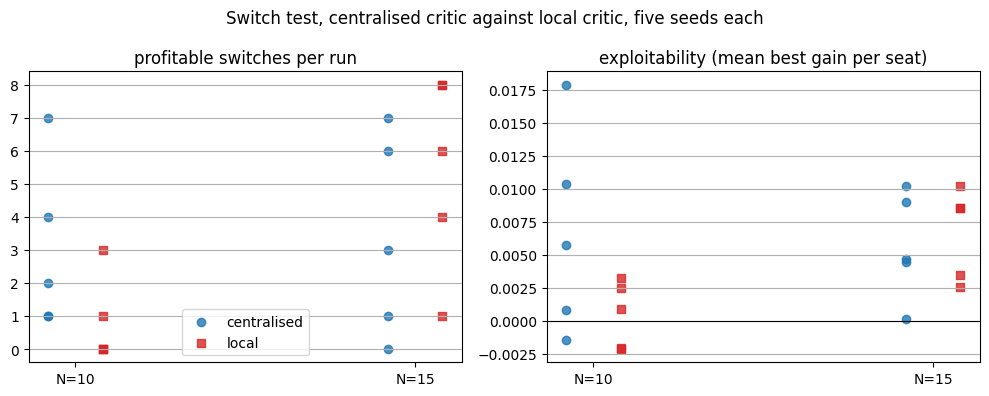

In [17]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
offsets = {"centralised": -0.08, "local": 0.08}
markers = {"centralised": "o", "local": "s"}
colours = {"centralised": "tab:blue", "local": "tab:red"}
panels = [("profitable switches per run", profitable_count),
          ("exploitability (mean best gain per seat)", exploitability)]
for axis, (title, measure) in zip(axes, panels):
    for arm in ARMS:
        for n_index in range(len(PLAYER_COUNTS)):
            n = PLAYER_COUNTS[n_index]
            values = [measure(R[(n, arm, seed)]) for seed in SEEDS]
            label = arm if n_index == 0 else None
            axis.scatter([n_index + offsets[arm]] * len(values), values, marker=markers[arm],
                         color=colours[arm], label=label, alpha=0.8)
    axis.set_xticks(range(len(PLAYER_COUNTS)))
    axis.set_xticklabels(["N=%d" % n for n in PLAYER_COUNTS])
    axis.set_title(title)
    axis.grid(True, axis="y")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[0].legend()
figure.suptitle("Switch test, centralised critic against local critic, five seeds each")
figure.tight_layout()
plt.show()

## What this step establishes, derived from the measurements

In [18]:
print("centralised arm reproduces step 1:", reproduces_step1)
print()
for n in PLAYER_COUNTS:
    for arm in ARMS:
        lefts = sum(1 for seed in SEEDS if MODE[(n, arm, seed)] == "left")
        print("  N=%-3d %-11s fires left in %d of %d seeds" % (n, arm, lefts, len(SEEDS)))
print()
summary_rows = [("profitable switches", SWITCH_COUNT), ("exploitability", EXPLOIT),
                ("weakest advantage", ADVANTAGE), ("distance from next_weaker", DISTANCE_TO_RULE),
                ("explained variance", EV)]
for n in PLAYER_COUNTS:
    print("  N=%d" % n)
    for label, table in summary_rows:
        central, local, gap, error, verdict = table[n]
        print("    %-28s centralised %.4f  local %.4f  difference %+.4f (s.e. %.4f)  %s"
              % (label, mean_of(central), mean_of(local), gap, error, verdict))
    print()

equilibrium_verdicts = []
for n in PLAYER_COUNTS:
    equilibrium_verdicts.append((n, SWITCH_COUNT[n][4], EXPLOIT[n][4]))
helped = [n for n, count_verdict, exploit_verdict in equilibrium_verdicts
          if "centralised better" in (count_verdict, exploit_verdict)]
hurt = [n for n, count_verdict, exploit_verdict in equilibrium_verdicts
        if "local better" in (count_verdict, exploit_verdict)]
if helped:
    print("On the switch test the centralised critic is measurably closer to an equilibrium at N =", helped)
if hurt:
    print("On the switch test the local critic is measurably closer to an equilibrium at N =", hurt)
if not helped and not hurt:
    print("On the switch test neither critic is measurably closer to an equilibrium at 10 or 15 players.")

centralised arm reproduces step 1: True

  N=10  centralised fires left in 3 of 5 seeds
  N=10  local       fires left in 4 of 5 seeds
  N=15  centralised fires left in 4 of 5 seeds
  N=15  local       fires left in 5 of 5 seeds

  N=10
    profitable switches          centralised 3.0000  local 0.8000  difference +2.2000 (s.e. 1.2410)  no measurable difference
    exploitability               centralised 0.0067  local 0.0005  difference +0.0062 (s.e. 0.0037)  no measurable difference
    weakest advantage            centralised 1.3128  local 1.5226  difference -0.2098 (s.e. 0.2281)  no measurable difference
    distance from next_weaker    centralised 0.3105  local 0.1895  difference +0.1210 (s.e. 0.2470)  no measurable difference
    explained variance           centralised 0.2150  local 0.2312  difference -0.0161 (s.e. 0.0052)  local better

  N=15
    profitable switches          centralised 3.4000  local 5.4000  difference -2.0000 (s.e. 1.9748)  no measurable difference
    exploit

## Reproducibility

Every job in the script seeds itself, so one job run twice must give an identical result file.
Checked here on a shortened job (five updates, small measurements), which exercises the same
code path in seconds.

In [19]:
def shortened_job():
    saved = (script.UPDATES, script.EVALUATION_EPISODES, script.BASELINE_EPISODES,
             script.SWITCH_EPISODES, script.CRITIC_EPISODES)
    script.UPDATES = 5
    script.EVALUATION_EPISODES = 200
    script.BASELINE_EPISODES = 200
    script.SWITCH_EPISODES = 100
    script.CRITIC_EPISODES = 20
    try:
        model = script.train_one(10, "local", 0)
        game = GruelEnv(n=10, reward=script.REWARD, seating=script.SEATING, seed=5000)
        torch.manual_seed(7000)
        summary = script.summarise(script.play_episodes(game, script.make_agent_policy(model), 200), 10)
        summary["switch_test"] = script.switch_test(10, model, 0)
    finally:
        (script.UPDATES, script.EVALUATION_EPISODES, script.BASELINE_EPISODES,
         script.SWITCH_EPISODES, script.CRITIC_EPISODES) = saved
    return json.dumps(summary, sort_keys=True)


first = shortened_job()
second = shortened_job()
print("identical:", first == second)

identical: True
